# Network Science HS26 – Assignment
## Bioinformatics Network Investigation: an enzyme structural graph

This notebook contains all calculations and figures for the report.
It starts from the supplied edge list `dataset/edgelist.txt`.

In [1]:
import sys
import networkx as nx
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from collections import Counter

SEED = 42

print("Python    ", sys.version.split()[0])
print("networkx  ", nx.__version__)
print("numpy     ", np.__version__)
print("scipy     ", scipy.__version__)
print("matplotlib", matplotlib.__version__)

Python     3.9.6
networkx   3.2.1
numpy      2.0.2
scipy      1.13.1
matplotlib 3.9.4


## 0. Data: loading and sanity checks

In [2]:
EDGE_FILE = "dataset/edgelist.txt"

with open(EDGE_FILE) as f:
    rows = [tuple(map(int, line.split())) for line in f if line.strip()]

row_set = set(rows)
reverse_listed = sum((b, a) in row_set for (a, b) in rows)

print("Rows in file:", len(rows))
print("Rows whose reverse is also listed:", reverse_listed)


G = nx.read_edgelist(EDGE_FILE, nodetype=int)

print(G)
print("Self-loops:", nx.number_of_selfloops(G))
print("Node IDs from", min(G.nodes()), "to", max(G.nodes()))

Rows in file: 220
Rows whose reverse is also listed: 220
Graph with 51 nodes and 110 edges
Self-loops: 0
Node IDs from 1 to 51


### Findings (0. Data)

- **Measurement:** The file has 220 rows. For every row (a, b), the reversed row (b, a) is also present.

- **Observation:** Every undirected edge is listed in both directions.

- **Consequence:** Loaded as an undirected graph, the duplicates merge: the network has
N = 51 nodes (IDs 1–51, no gaps), L = 110 edges and no self-loops.
All further analysis uses this simple undirected graph.

## Null models (helper functions)

All comparisons use the same procedure: compute a statistic on the real network,
compute it again on many randomised networks from a null model and report where the
real value lies in that distribution. Each random network gets its own fixed seed,
so all results are reproducible.
All tests use the significance level α = 0.05, fixed in advance.

In [3]:
def er_null(G, seed):
    """ER G(N, L): same number of nodes and links, links placed at random."""
    return nx.gnm_random_graph(G.number_of_nodes(), G.number_of_edges(), seed=seed)


def degree_preserving_null(G, seed):
    """Degree-preserving randomisation by link swaps."""
    H = G.copy()
    nx.double_edge_swap(H, nswap=10 * H.number_of_edges(), max_tries = 1000 * H.number_of_edges(), seed=seed)
    return H


def null_test(G, statistic, null_model, direction, n_samples=1000, seed=SEED):
    """Compare statistic(G) with its values in n_samples null-model networks.
    
    direction = "greater":   p = share of null values >= observed
    direction = "less":      p = share of null values <= observed
    direction = "two-sided": p = 2 * the smaller of the two shares (capped at 1)
    """


    observed = statistic(G)
    values = np.array([statistic(null_model(G, seed=seed + i)) for i in range(n_samples)])
    values = values[~np.isnan(values)]          # drop samples where the statistic is undefined
    n_valid = len(values)
    if direction == "greater":
        # p = how often chance gives a value as large as ours or larger
        p = np.mean(values >= observed)
        p_min = 1 / n_valid
    elif direction == "less":
        # p = how often chance gives a value as small as ours or smaller
        p = np.mean(values <= observed)
        p_min = 1 / n_valid
    elif direction == "two-sided":
        # p = how often chance gives a value at least as far out as ours, on either side
        p = min(1.0, 2 * min(np.mean(values >= observed), np.mean(values <= observed)))
        p_min = 2 / n_valid
    else:
        raise ValueError('direction must be "greater", "less" or "two-sided"')
    return {
        "observed": observed,
        "values": values,
        "n_valid": len(values),
        "null_mean": values.mean(),
        "null_std": values.std(),
        "p": p,
        "p_min": p_min,
    }

def p_text(res):
    """p-value as text. If no null value was as extreme, we can only say p < p_min."""
    if res["p"] == 0:
        return f"p < {res['p_min']:.3f}"
    return f"p = {res['p']:.3f}"

## 1. Global Structure

**Question:** What does the network look like as a whole? Is it one connected piece,
how dense is it and how far apart are nodes?

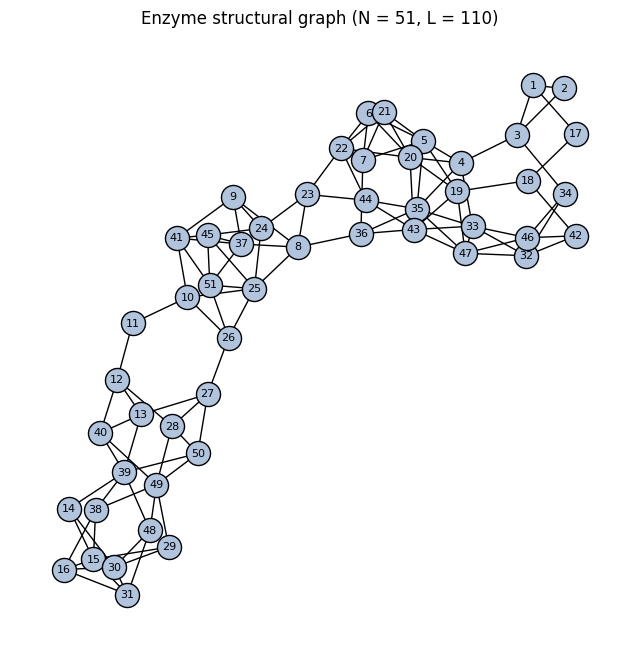

In [4]:
pos = nx.kamada_kawai_layout(G)

fig, ax = plt.subplots(figsize=(8, 8))
nx.draw_networkx(G, pos, ax=ax, node_size=300, node_color="lightsteelblue",
                 edgecolors="black", font_size=8)
ax.set_title(f"Enzyme structural graph (N = {G.number_of_nodes()}, L = {G.number_of_edges()})")
ax.axis("off")
plt.show()

In [5]:
N = G.number_of_nodes()
L = G.number_of_edges()
k_avg = 2 * L / N
density = nx.density(G)
ecc = nx.eccentricity(G)

print("Connected:", nx.is_connected(G))
print("Number of components:", nx.number_connected_components(G))
print(f"Average degree <k> = {k_avg:.2f}")
print(f"Density = {density:.3f}")
print(f"Average distance <d> = {nx.average_shortest_path_length(G):.2f}")
print("Diameter (largest eccentricity) =", max(ecc.values()))
print("Smallest eccentricity =", min(ecc.values()))
print("Center (smallest eccentricity):", nx.center(G, e=ecc))
print("Periphery (largest eccentricity):", sorted(nx.periphery(G, e=ecc)))
print(f"ln N = {np.log(N):.2f}")

Connected: True
Number of components: 1
Average degree <k> = 4.31
Density = 0.086
Average distance <d> = 5.04
Diameter (largest eccentricity) = 12
Smallest eccentricity = 6
Center (smallest eccentricity): [25]
Periphery (largest eccentricity): [1, 2, 15, 16, 17, 30, 31, 34, 42]
ln N = 3.93


Symmetric: True
Number of 1s: 220 = 2 * L


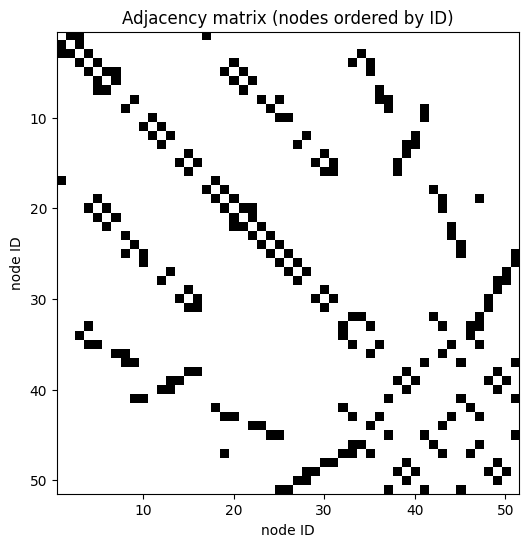

In [6]:
nodes = sorted(G.nodes())
A = nx.to_numpy_array(G, nodelist=nodes)

print("Symmetric:", np.array_equal(A, A.T))
print("Number of 1s:", int(A.sum()), "= 2 * L")

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(A, cmap="Greys", extent=(0.5, N + 0.5, N + 0.5, 0.5))
ax.set_xlabel("node ID")
ax.set_ylabel("node ID")
ax.set_title("Adjacency matrix (nodes ordered by ID)")
plt.show()

### Findings (1. Global Structure)

- **Measurement:** The network is connected (one component) with N = 51, L = 110,
average degree ⟨k⟩ = 4.31 and density 0.086. The average distance is ⟨d⟩ = 5.04
and the diameter (largest eccentricity) is 12. The smallest eccentricity is 6,
reached only by node 25.

- **Observation (drawing):** In the Kamada–Kawai drawing, the network appears elongated,
like a chain of denser regions. The periphery nodes appear at the two opposite ends
({1, 2, 17, 34, 42} and {15, 16, 30, 31}) and node 25 near the middle. Some regions seem
to be joined by only a few links (e.g. node 11, which has only two neighbours, 10 and 12).


- **Observation (adjacency matrix):** Many links lie close to the diagonal, so nodes with
consecutive IDs often seem to be linked (e.g. 5–6, 6–7). There are also short lines of links
parallel to the diagonal, where both IDs increase together (e.g. 4–20, 5–21, 6–22) and lines
perpendicular to the diagonal, where one ID increases while the other decreases
(e.g. 31–48, 32–47, 33–46). These patterns concern the node labels rather than the structure itself and are not analysed further.

- **Interpretation (preliminary):** The drawing suggests an elongated shape, but a drawing
depends on the layout algorithm, so this is not yet evidence. Whether the measured
distances are long for a network of this size is tested against null models.

### Are the distances long? (null-model comparison)

We compare ⟨d⟩ and the diameter with two null models (1000 networks each):
- **ER G(N, L):** keeps only N and L. Tests whether the distances are more than a consequence of size and density.

- **Degree-preserving randomisation:** keeps every node's degree. Tests whether they are more than a consequence of the degrees.

Direction: "greater", i.e. are the real distances longer than random?

Average distance and diameter are only defined for connected networks, so disconnected
ER networks are left out. The number of valid samples is reported.

In [7]:
def avg_distance(G):
    """Average distance <d>; undefined (nan) if G is disconnected."""
    return nx.average_shortest_path_length(G) if nx.is_connected(G) else np.nan


def diameter(G):
    """Diameter; undefined (nan) if G is disconnected."""
    return nx.diameter(G) if nx.is_connected(G) else np.nan


distance_results = {}
for stat_name, stat in [("<d>", avg_distance), ("diameter", diameter)]:
    for model_name, model in [("ER", er_null), ("degree-preserving", degree_preserving_null)]:
        res = null_test(G, stat, model, direction="greater")
        distance_results[(stat_name, model_name)] = res
        print(f"{stat_name:8} | {model_name:17} | observed = {res['observed']:5.2f} | "
              f"null mean = {res['null_mean']:.2f} ± {res['null_std']:.2f} | "
              f"valid = {res['n_valid']:4} | {p_text(res)}")

<d>      | ER                | observed =  5.04 | null mean = 2.80 ± 0.05 | valid =  594 | p < 0.002
<d>      | degree-preserving | observed =  5.04 | null mean = 2.80 ± 0.03 | valid = 1000 | p < 0.001
diameter | ER                | observed = 12.00 | null mean = 5.72 ± 0.63 | valid =  594 | p < 0.002
diameter | degree-preserving | observed = 12.00 | null mean = 5.11 ± 0.32 | valid = 1000 | p < 0.001


- **Measurement (null-model comparison):** Compared with 1000 ER networks G(N, L)
(594 of them connected and used) and 1000 degree-preserving randomisations (all connected),
the real distances are much longer: ⟨d⟩ = 5.04 vs 2.80 ± 0.05 (ER) and 2.80 ± 0.03
(degree-preserving); diameter 12 vs 5.72 ± 0.63 (ER) and 5.11 ± 0.32 (degree-preserving).
None of the random networks reached the real values (p < 0.002 for ER, p < 0.001 for
degree-preserving; direction "greater" fixed in advance).

- **Interpretation:** At α = 0.05 we reject both null hypotheses: the long distances are not a
consequence of the size and density alone, nor of the degrees alone, but of how the nodes are
wired. The test does not show which wiring pattern is responsible; the elongated appearance
of the drawing would fit, but a drawing is not evidence. This is examined in the
following sections.

## 2. Degree Structure

**Question:** How are the links distributed over the nodes? Are there hubs or do all nodes
have a similar number of neighbours? Is this distribution what we would expect by chance?

In [8]:
degrees = dict(G.degree())
k = np.array(list(degrees.values()))

print(f"min k = {k.min()}, max k = {k.max()}, <k> = {k.mean():.2f}, sigma_k = {k.std():.2f}")

values, counts = np.unique(k, return_counts=True)
for value, count in zip(values, counts):
    nodes_with_k = sorted(n for n, d in degrees.items() if d == value)
    print(f"k = {value}: {count:2} nodes  {nodes_with_k}")

min k = 2, max k = 6, <k> = 4.31, sigma_k = 1.08
k = 2:  3 nodes  [2, 11, 17]
k = 3:  6 nodes  [1, 14, 18, 29, 34, 42]
k = 4: 23 nodes  [3, 6, 7, 9, 10, 12, 13, 16, 21, 23, 24, 26, 27, 28, 31, 32, 36, 38, 40, 44, 46, 48, 50]
k = 5: 10 nodes  [4, 8, 15, 19, 22, 30, 37, 41, 45, 51]
k = 6:  9 nodes  [5, 20, 25, 33, 35, 39, 43, 47, 49]


### Are the degrees what we would expect by chance? (null-model comparison)

We compare two measures with 1000 ER networks G(N, L):
- **k_max** (largest degree): are there hubs or is the largest degree unusually small?

- **σ_k** (standard deviation of the degrees): are the degrees more or less spread out than by chance?

**Null model:** only ER, which keeps N and L. Degree-preserving randomisation keeps every degree
fixed, so it would reproduce exactly the measured values and cannot test them.

**Direction:** two-sided, because the question asks whether the degrees differ from chance in
either direction.

In [9]:
def k_max(G):
    """Largest degree."""
    return max(d for _, d in G.degree())


def sigma_k(G):
    """Standard deviation of the degrees."""
    return np.std([d for _, d in G.degree()])


degree_results = {}
for stat_name, stat in [("k_max", k_max), ("sigma_k", sigma_k)]:
    res = null_test(G, stat, er_null, direction="two-sided")
    degree_results[stat_name] = res
    print(f"{stat_name:7} | ER | observed = {res['observed']:5.2f} | "
          f"null mean = {res['null_mean']:.2f} ± {res['null_std']:.2f} | "
          f"valid = {res['n_valid']:4} | {p_text(res)}")

k_max   | ER | observed =  6.00 | null mean = 9.20 ± 1.13 | valid = 1000 | p < 0.002
sigma_k | ER | observed =  1.08 | null mean = 1.93 ± 0.19 | valid = 1000 | p < 0.002


### Findings (2. Degree Structure)

- **Measurement:** Degrees range from 2 to 6 (⟨k⟩ = 4.31, σ_k = 1.08); no node has degree 0 or 1.
23 of the 51 nodes (45%) have degree 4. Lowest degree (k = 2): nodes 2, 11 and 17.
Highest degree (k = 6): nodes 5, 20, 25, 33, 35, 39, 43, 47 and 49.

- **Measurement (null-model comparison):** Compared with 1000 ER networks G(N, L), both the largest
degree and the spread of the degrees are smaller than by chance: k_max = 6 vs 9.20 ± 1.13 and
σ_k = 1.08 vs 1.93 ± 0.19 (two-sided, p < 0.002 for both; no ER network had values this small).

- **Observation:** The degree-2 nodes 2 and 17 belong to the periphery found in Section 1 and node 11
is the node with only two neighbours (10 and 12) noted in the drawing. Node 25, the centre,
has the maximum degree 6.

- **Interpretation:** At α = 0.05 we reject H0: the degrees are not what random placement of
L links among N nodes produces. The network has no hubs: its largest degree (6, about 1.4 ⟨k⟩)
is smaller than in every one of the 1000 ER networks, which themselves have no hubs. Its degrees
are also less spread out than by chance, concentrated in a narrow range around ⟨k⟩.
This is the opposite of the broad degree distributions typical of real networks.
The test does not show why the degrees are so uniform.

## 3. Local structure: Clustering

**Question:** Do the neighbours of a node tend to be linked to each other, i.e. does the network
contain more triangles than we would expect by chance?

In [10]:
C_i = nx.clustering(G)                              
C = np.mean(list(C_i.values()))                       

print(f"Clustering coefficient C = {C:.3f}")

C_max = max(C_i.values())
print("Nodes with C_i = 0:", sorted(n for n, c in C_i.items() if c == 0))
print(f"Nodes with the largest C_i ({C_max:.2f}):", sorted(n for n, c in C_i.items() if c == C_max))

Clustering coefficient C = 0.238
Nodes with C_i = 0: [11, 14, 17, 18, 29, 34, 36, 42]
Nodes with the largest C_i (1.00): [2]


### Does the network have more triangles than by chance? (null-model comparison)

We compare the clustering coefficient C with two null models (1000 networks each):
- **ER G(N, L):** keeps only N and L. Tests whether C is more than a consequence of size and density.

- **Degree-preserving randomisation:** keeps every node's degree. Tests whether C is more than
a consequence of the degrees.

**Direction:** "greater". Lecture notes that most real networks have a large
clustering coefficient, while ER networks have almost none.

In [11]:
def avg_clustering(G):
    """Clustering coefficient C: average of the local C_i."""
    return np.mean(list(nx.clustering(G).values()))


clustering_results = {}
for model_name, model in [("ER", er_null), ("degree-preserving", degree_preserving_null)]:
    res = null_test(G, avg_clustering, model, direction="greater")
    clustering_results[model_name] = res
    print(f"C | {model_name:17} | observed = {res['observed']:.3f} | "
          f"null mean = {res['null_mean']:.3f} ± {res['null_std']:.3f} | "
          f"valid = {res['n_valid']:4} | {p_text(res)}")

C | ER                | observed = 0.238 | null mean = 0.081 ± 0.026 | valid = 1000 | p < 0.001
C | degree-preserving | observed = 0.238 | null mean = 0.061 ± 0.022 | valid = 1000 | p < 0.001


### Findings (3. Clustering)

- **Measurement:** The clustering coefficient is C = 0.238: on average, about a quarter of the
pairs of a node's neighbours are linked. Eight nodes have C_i = 0 (11, 14, 17, 18, 29, 34, 36, 42),
most of them with degree 2 or 3.

- **Measurement (null-model comparison):** C is larger than in all 1000 ER networks
(0.081 ± 0.026, about 3 times smaller) and all 1000 degree-preserving randomisations
(0.061 ± 0.022, about 4 times smaller); p < 0.001 for both (direction "greater" fixed in advance).

- **Observation:** For low-degree nodes, C_i can take only a few values (for degree 2 only 0 or 1,
e.g. node 2 has C_i = 1), so single C_i values of such nodes are not used for claims.

- **Interpretation:** At α = 0.05 we reject both null hypotheses: the network contains more
triangles than its size and density or its degrees alone would produce. The neighbours of a node
are linked about 3–4 times as often as by chance. The test does not show where these triangles
are located or why they form.

## 4. Degree correlations: Assortativity

**Question:** Do nodes tend to be linked to nodes of similar degree (assortative), to nodes of
different degree (disassortative) or neither? Is this more than the degrees alone would produce?

In [12]:
r = nx.degree_assortativity_coefficient(G)
print(f"Degree assortativity r = {r:.3f}")

Degree assortativity r = 0.169


### Is the assortativity more than the degrees produce? (null-model comparison)

We compare r with 1000 degree-preserving randomisations. Only this null model is used: r is
computed from the degrees at both ends of each link, so a null model that changes the degrees (ER)
would mix the effect of the degrees with the effect of who is linked to whom.

**Direction:** two-sided, because no direction is expected in advance.

In [13]:
def assortativity(G):
    """Degree assortativity r: Pearson correlation of the degrees at both ends of each link."""
    return nx.degree_assortativity_coefficient(G)


res = null_test(G, assortativity, degree_preserving_null, direction="two-sided")
assortativity_result = res
print(f"r | degree-preserving | observed = {res['observed']:.3f} | "
      f"null mean = {res['null_mean']:.3f} ± {res['null_std']:.3f} | "
      f"valid = {res['n_valid']:4} | {p_text(res)}")

r | degree-preserving | observed = 0.169 | null mean = -0.025 ± 0.090 | valid = 1000 | p = 0.028


### Findings (4. Degree correlation)

- **Measurement:** The degree assortativity is r = 0.169: linked nodes tend to have slightly
similar degrees.

- **Measurement (null-model comparison):** In 1000 degree-preserving randomisations, r is
-0.025 ± 0.090; the observed value gives a two-sided p = 0.028.

- **Interpretation:** At α = 0.05 we reject H0: the slight assortativity is not explained by the
degrees alone. The evidence is much weaker than for distances, degrees and clustering
(p = 0.028 vs p < 0.002): it would not be rejected at α = 0.01. We therefore treat it as weak evidence that linked nodes tend to have similar degrees.

## 5. Centralities

**Question:** Which nodes are the most important and do the different centrality measures
(degree, closeness, betweenness, eigenvector) agree on which nodes these are?

In [14]:
centralities = {
    "degree": dict(G.degree()),
    "closeness": nx.closeness_centrality(G),
    "betweenness": nx.betweenness_centrality(G),
    "eigenvector": nx.eigenvector_centrality(G, max_iter=1000),
}

for name, c in centralities.items():
    ranked = sorted(c, key=c.get, reverse=True)        
    threshold = c[ranked[4]]                           
    top = [n for n in ranked if c[n] >= threshold]     
    print(f"{name:11}:", ", ".join(f"{n} ({c[n]:.3g})" for n in top))

degree     : 5 (6), 20 (6), 33 (6), 35 (6), 25 (6), 39 (6), 43 (6), 47 (6), 49 (6)
closeness  : 8 (0.276), 25 (0.27), 36 (0.265), 26 (0.253), 23 (0.249), 24 (0.249)
betweenness: 8 (0.438), 25 (0.432), 26 (0.381), 36 (0.381), 27 (0.366)
eigenvector: 43 (0.307), 35 (0.307), 33 (0.301), 47 (0.301), 20 (0.283)


In [15]:
names = list(centralities)                     
nodes = sorted(G.nodes())                      
values = np.array([[centralities[name][n] for n in nodes] for name in names])
corr = np.corrcoef(values)                     # Pearson r between every pair of measures

print(" " * 12 + "".join(f"{name:>12}" for name in names))
for name, row in zip(names, corr):
    print(f"{name:12}" + "".join(f"{r:12.2f}" for r in row))

                  degree   closeness betweenness eigenvector
degree              1.00        0.40        0.27        0.53
closeness           0.40        1.00        0.61        0.46
betweenness         0.27        0.61        1.00        0.07
eigenvector         0.53        0.46        0.07        1.00


In [16]:
for name, c in centralities.items():
    ranked = sorted(c, key=c.get, reverse=True)
    threshold = c[ranked[4]]
    top = [n for n in ranked if c[n] >= threshold]          
    next_value = c[ranked[len(top)]]                         
    links = sorted(tuple(sorted(e)) for e in G.subgraph(top).edges())
    print(f"{name}: top {top}, lowest in group {threshold:.3g}, next {next_value:.3g}")
    print(f"   links within the group ({len(links)}): {links}")
    print(f"   group is connected: {nx.is_connected(G.subgraph(top))}\n")

degree: top [5, 20, 33, 35, 25, 39, 43, 47, 49], lowest in group 6, next 5
   links within the group (7): [(5, 35), (20, 43), (33, 35), (33, 43), (33, 47), (35, 47), (43, 47)]
   group is connected: False

closeness: top [8, 25, 36, 26, 23, 24], lowest in group 0.249, next 0.246
   links within the group (6): [(8, 23), (8, 25), (8, 36), (23, 24), (24, 25), (25, 26)]
   group is connected: True

betweenness: top [8, 25, 26, 36, 27], lowest in group 0.366, next 0.187
   links within the group (4): [(8, 25), (8, 36), (25, 26), (26, 27)]
   group is connected: True

eigenvector: top [43, 35, 33, 47, 20], lowest in group 0.283, next 0.278
   links within the group (6): [(20, 43), (33, 35), (33, 43), (33, 47), (35, 47), (43, 47)]
   group is connected: True



### Findings (5. Centralities)

- **Measurement:** The four centralities rank different nodes highest. Degree: nine nodes tie at
k = 6 (5, 20, 25, 33, 35, 39, 43, 47, 49). Closeness: 8, 25, 36, 26, 23, 24. Betweenness: 8, 25,
26, 36, 27. Eigenvector: 43, 35, 33, 47, 20. Pearson correlations between the measures range from
0.07 (betweenness–eigenvector) to 0.61 (closeness–betweenness).

- **Measurement (top groups):** For each measure, we checked the links among its top five nodes
(plus ties).

    - Betweenness: the five nodes form the path 36–8–25–26–27, with node 25 in its middle. There is a
    clear gap after this group (0.366 vs 0.187 for the next node).

    - Eigenvector: the five nodes are densely linked (6 of 10 possible links, including the triangles
    33–35–47 and 33–43–47). There is no clear gap after this group (0.283 vs 0.278).

    - Closeness: the six nodes form one connected group around nodes 8 and 25. There is no clear gap
    (0.249 vs 0.246).

    - Degree: the nine degree-6 nodes do not form one connected group; five of them (20, 33, 35, 43, 47)
    are the eigenvector group.

- **Observation:** Nodes 26, 27 and 36 have degree 4, the most common degree, yet are among the five
nodes with the highest betweenness. Node 25 is the only node near the top of degree, closeness and
betweenness and it is also the centre found in Section 1 (smallest eccentricity).

- **Interpretation:** The notions of importance do not agree in this network and they select different nodes. Betweenness (and largely closeness) selects a path of five nodes with
ordinary degrees, each lying on roughly 37–44% of the shortest paths between other nodes, so many
shortest routes between different parts of the network run along it. Eigenvector centrality
instead selects a densely linked group of high-degree nodes. For closeness and
eigenvector, the top-five cut-off is our choice (no clear gap), so the exact membership of these
groups is not sharp. Whether the network depends on the path to stay connected is not shown here.

## 6. Communities

**Question:** Does the network contain groups of nodes that are more strongly linked to one another
than to the rest of the network? If so, how convincing is this structure and which nodes or links
are particularly relevant?

In [17]:
communities = nx.community.louvain_communities(G, seed=SEED)
communities = sorted(communities, key=min)          
Q = nx.community.modularity(G, communities)

print(f"Louvain: {len(communities)} communities, Q = {Q:.3f}")
for a, com in enumerate(communities, start=1):
    print(f"  community {a} ({len(com)} nodes): {sorted(com)}")

Louvain: 5 communities, Q = 0.613
  community 1 (4 nodes): [1, 2, 3, 17]
  community 2 (7 nodes): [4, 5, 6, 7, 20, 21, 22]
  community 3 (11 nodes): [8, 9, 10, 23, 24, 25, 26, 37, 41, 45, 51]
  community 4 (17 nodes): [11, 12, 13, 14, 15, 16, 27, 28, 29, 30, 31, 38, 39, 40, 48, 49, 50]
  community 5 (12 nodes): [18, 19, 32, 33, 34, 35, 36, 42, 43, 44, 46, 47]


In [18]:
print("comm  N  L_int  k_int  k_ext  density  weak  strong  nodes with k_i_int <= k_i_ext")
for a, com in enumerate(communities, start=1):
    N_a = len(com)
    L_a = G.subgraph(com).number_of_edges()                  
    k_a = sum(G.degree(n) for n in com)                       
    k_int = 2 * L_a                                           
    k_ext = k_a - k_int                                       
    density = 2 * L_a / (N_a * (N_a - 1))                     
    failing = sorted(n for n in com
                     if sum(nb in com for nb in G[n]) <= sum(nb not in com for nb in G[n]))
    print(f"{a:4} {N_a:2} {L_a:6} {k_int:6} {k_ext:6} {density:8.2f}  {str(k_int > k_ext):5} "
          f"{str(not failing):6}  {failing}")

L_between = G.number_of_edges() - sum(G.subgraph(com).number_of_edges() for com in communities)
print(f"\nLinks between communities: {L_between} of {G.number_of_edges()} "
      f"({L_between / G.number_of_edges():.0%}); network density: {nx.density(G):.3f}")

comm  N  L_int  k_int  k_ext  density  weak  strong  nodes with k_i_int <= k_i_ext
   1  4      4      8      3     0.67  True  False   [3, 17]
   2  7     12     24     10     0.57  True  False   [4]
   3 11     23     46      5     0.42  True  False   [23]
   4 17     34     68      2     0.25  True  False   [11]
   5 12     21     42     12     0.32  True  False   [36, 44]

Links between communities: 16 of 110 (15%); network density: 0.086


### Is the community structure more than chance? (null-model comparison)

A search for the partition of highest modularity finds Q well above zero even in random networks. We therefore compare the Q found by Louvain in the real network with the Q that Louvain
finds in each of 1000 degree-preserving randomisations: the search is repeated in every random
network. Degree-preserving randomisation is used because modularity itself measures internal links
against a null model that keeps the degrees.

**Direction (fixed in advance):** "greater", i.e. does the real network have stronger community
structure than random networks with the same degrees?

In [19]:
def louvain_Q(G):
    """Modularity Q of the partition found by Louvain (fixed seed)."""
    return nx.community.modularity(G, nx.community.louvain_communities(G, seed=SEED))


community_result = null_test(G, louvain_Q, degree_preserving_null, direction="greater")
res = community_result
print(f"Q | degree-preserving | observed = {res['observed']:.3f} | "
      f"null mean = {res['null_mean']:.3f} ± {res['null_std']:.3f} | "
      f"valid = {res['n_valid']:4} | {p_text(res)}")

Q | degree-preserving | observed = 0.613 | null mean = 0.409 ± 0.019 | valid = 1000 | p < 0.001


In [20]:
louvain_of = {}
for a, com in enumerate(communities, start=1):
    for n in com:
        louvain_of[n] = a

print(louvain_of)

{1: 1, 2: 1, 3: 1, 17: 1, 7: 2, 21: 2, 5: 2, 6: 2, 20: 2, 4: 2, 22: 2, 37: 3, 8: 3, 41: 3, 10: 3, 9: 3, 45: 3, 51: 3, 23: 3, 24: 3, 25: 3, 26: 3, 11: 4, 12: 4, 13: 4, 14: 4, 15: 4, 16: 4, 27: 4, 28: 4, 29: 4, 30: 4, 31: 4, 38: 4, 39: 4, 40: 4, 48: 4, 49: 4, 50: 4, 32: 5, 33: 5, 34: 5, 35: 5, 36: 5, 42: 5, 43: 5, 44: 5, 46: 5, 47: 5, 18: 5, 19: 5}


In [21]:
lpa = nx.community.asyn_lpa_communities(G, seed=SEED)
lpa = sorted(lpa, key=min)

gn_levels = nx.community.girvan_newman(G)
gn = max(gn_levels, key=lambda part: nx.community.modularity(G, part))
gn = sorted(gn, key=min)

louvain_res2 = nx.community.louvain_communities(G, resolution=2, seed=SEED)
louvain_res2 = sorted(louvain_res2, key=min)

In [22]:
others = {
    "Label propagation": lpa,
    "Edge betweenness": gn,
    "Louvain, resolution 2": louvain_res2,
}

for name, part in others.items():
    Q_part = nx.community.modularity(G, part)
    print(f"{name}: {len(part)} communities, Q = {Q_part:.3f}")

    for com in part:
        origin = Counter(louvain_of[n] for n in com)
        origin = dict(sorted(origin.items()))
        print(f"   {sorted(com)}  <- from Louvain communities {origin}")

    print("\n")

Label propagation: 11 communities, Q = 0.513
   [1, 2, 3]  <- from Louvain communities {1: 3}
   [4, 5, 35, 44]  <- from Louvain communities {2: 2, 5: 2}
   [6, 22]  <- from Louvain communities {2: 2}
   [7, 21]  <- from Louvain communities {2: 2}
   [8, 9, 10, 11, 23, 24, 25, 26, 37, 41, 45, 51]  <- from Louvain communities {3: 11, 4: 1}
   [12, 13, 40]  <- from Louvain communities {4: 3}
   [14, 15, 16, 29, 30, 31, 38, 39, 48, 49]  <- from Louvain communities {4: 10}
   [17, 18]  <- from Louvain communities {1: 1, 5: 1}
   [19, 20, 36, 43]  <- from Louvain communities {2: 1, 5: 3}
   [27, 28, 50]  <- from Louvain communities {4: 3}
   [32, 33, 34, 42, 46, 47]  <- from Louvain communities {5: 6}


Edge betweenness: 6 communities, Q = 0.611
   [1, 2, 3, 17, 18]  <- from Louvain communities {1: 4, 5: 1}
   [4, 5, 6, 7, 19, 20, 21, 22, 33, 35, 36, 43, 44, 47]  <- from Louvain communities {2: 7, 5: 7}
   [8, 9, 10, 23, 24, 25, 26, 37, 41, 45, 51]  <- from Louvain communities {3: 11}
   [1

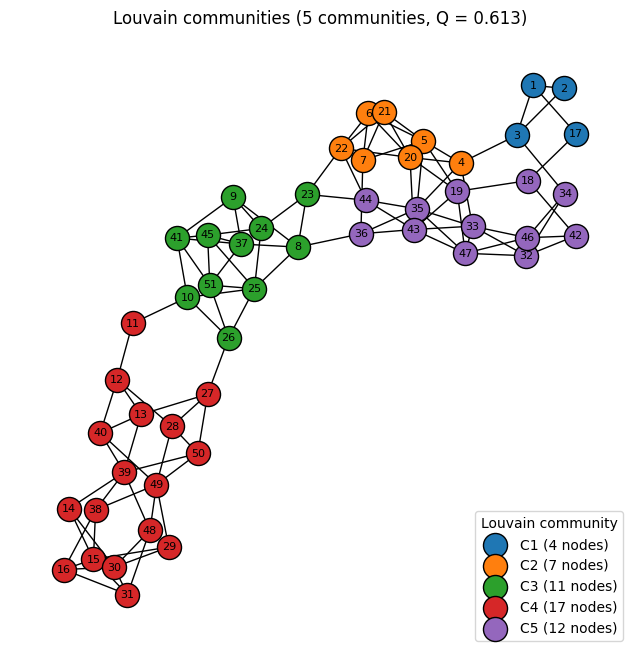

In [23]:
palette = plt.get_cmap("tab10")                      

fig, ax = plt.subplots(figsize=(8, 8))
nx.draw_networkx_edges(G, pos, ax=ax)
for a, com in enumerate(communities, start=1):
    nx.draw_networkx_nodes(G, pos, nodelist=sorted(com), ax=ax,
                           node_color=[palette(a - 1)], node_size=300, edgecolors="black",
                           label=f"C{a} ({len(com)} nodes)")
nx.draw_networkx_labels(G, pos, ax=ax, font_size=8)
ax.legend(loc="lower right", title="Louvain community")
ax.set_title(f"Louvain communities ({len(communities)} communities, Q = {Q:.3f})")
ax.axis("off")
plt.show()

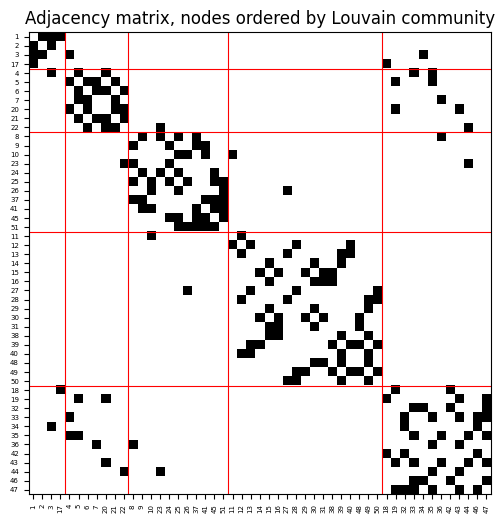

In [24]:
order = [n for com in communities for n in sorted(com)]    
A_comm = nx.to_numpy_array(G, nodelist=order)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(A_comm, cmap="Greys")

boundaries = np.cumsum([len(com) for com in communities])[:-1]   
for b in boundaries:
    ax.axhline(b - 0.5, color="red", linewidth=0.8)
    ax.axvline(b - 0.5, color="red", linewidth=0.8)

ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, fontsize=5, rotation=90)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=5)
ax.set_title("Adjacency matrix, nodes ordered by Louvain community")
plt.show()

### Findings (6. Communities)

- **Measurement (Louvain):** Louvain (fixed seed) finds 5 communities with Q = 0.613:
C1 = {1, 2, 3, 17}, C2 = {4, 5, 6, 7, 20, 21, 22}, C3 = {8, 9, 10, 23, 24, 25, 26, 37, 41, 45, 51},
C4 = {11–16, 27–31, 38–40, 48–50} (17 nodes), C5 = {18, 19, 32–36, 42–44, 46, 47} (12 nodes).

- **Measurement (cohesion and separation):** The internal link density of the communities is
0.25–0.67, compared with 0.086 for the whole network. 16 of the 110 links (15%) run between
communities. All five communities are weak communities (more internal than external links), none
is strong: nodes 3, 17 (C1), 4 (C2), 23 (C3), 11 (C4), 36 and 44 (C5) have at least as many links
outside their community as inside. C4 (17 nodes, 34 internal links) has only two external links
(k_ext = 2).

- **Measurement (null-model comparison):** In 1000 degree-preserving randomisations, Louvain finds
Q = 0.409 ± 0.019; none reaches the real Q = 0.613 (p < 0.001, direction "greater" fixed in advance).

- **Measurement (other algorithms):** Label propagation (11 communities, Q = 0.513), edge betweenness
  (6 communities, Q = 0.611) and Louvain with resolution γ = 2 (7 communities, Q = 0.581) were
  compared with the Louvain partition:

  - C3 is found almost unchanged by all three methods.

  - The nodes of C4 stay together (except node 11), but label propagation and γ = 2 split them into
smaller groups.

  - The nodes of C2 and C5 are grouped differently by each method.

- **Observation:** The nodes that change community between methods (e.g. 11, 17, 18, 23, 35, 36, 44)
are largely the same nodes that fail the strong-community condition. The path of high-betweenness
nodes from Section 5 runs from C5 (node 36) through C3 (8, 25, 26) into C4 (node 27). In the
drawing, the communities appear arranged in a row: C1 – C2/C5 – C3 – C4.

- **Interpretation:** At α = 0.05 we reject H0: the network has stronger community structure than
random networks with the same degrees. The most convincing parts are C3 and the separation of C4,
which all methods reproduce apart from the placement of node 11; C4 is attached to the rest of the
network by only two links, but may itself consist of two or three smaller groups. The border
between C2 and C5 is ambiguous. The partition is one good partition found by a heuristic, not
provably the best and modularity maximisation can merge small communities (resolution limit).

## 7. Random, small-world, scale-free or lattice-like?

**Question:** Which characteristics of random, small-world or scale-free networks does the network
show? Following the Lecture, we place its average distance and clustering between the two reference
points: random networks (from Sections 1 and 3) and a ring lattice with the same number of nodes.

In [25]:
ring = nx.watts_strogatz_graph(N, 4, 0)    

rows = [
    ("ER (mean of random networks)",
     distance_results[("<d>", "ER")]["null_mean"],
     distance_results[("diameter", "ER")]["null_mean"],
     clustering_results["ER"]["null_mean"]),
    ("degree-preserving (mean)",
     distance_results[("<d>", "degree-preserving")]["null_mean"],
     distance_results[("diameter", "degree-preserving")]["null_mean"],
     clustering_results["degree-preserving"]["null_mean"]),
    ("our network",
     nx.average_shortest_path_length(G), nx.diameter(G), avg_clustering(G)),
    ("ring lattice (k = 4)",
     nx.average_shortest_path_length(ring), nx.diameter(ring), avg_clustering(ring)),
]

print(f"{'network':30} {'<d>':>6} {'diameter':>9} {'C':>6}")
for name, d, diam, c in rows:
    print(f"{name:30} {d:6.2f} {diam:9.1f} {c:6.3f}")

network                           <d>  diameter      C
ER (mean of random networks)     2.80       5.7  0.081
degree-preserving (mean)         2.80       5.1  0.061
our network                      5.04      12.0  0.238
ring lattice (k = 4)             6.76      13.0  0.500


### Findings (7. Random, small-world, scale-free or lattice-like?)

- **Measurement:** Average distance, diameter and clustering of the network compared with the two
reference points of the Lecture:

  | | ⟨d⟩ | diameter | C |
  |---|---|---|---|
  | ER (mean of 1000) | 2.80 | 5.7 | 0.081 |
  | degree-preserving (mean of 1000) | 2.80 | 5.1 | 0.061 |
  | **our network** | **5.04** | **12** | **0.238** |
  | ring lattice (κ = 2, k = 4, N = 51) | 6.76 | 13 | 0.500 |

- **Observation:** On the scale from random to lattice, the average distance lies a bit more than
halfway towards the lattice ((5.04 − 2.80) / (6.76 − 2.80) ≈ 0.57), the diameter almost at the
lattice value and the clustering about a third of the way ((0.238 − 0.081) / (0.500 − 0.081) ≈ 0.37).

- **Interpretation:**

  - *Random:* no. Distances (Section 1), degrees (Section 2), clustering (Section 3) and community
    structure (Section 6) all differ significantly from random networks.

  - *Scale-free:* no. The degrees range only from 2 to 6, there are no hubs and the degree spread is
    even smaller than in ER networks (Section 2).

  - *Small-world:* no, in the sense of the Lecture. For: the clustering is clearly higher than in random
    networks. Against: the distances are not "almost as short as in a random network" but close to
    twice as long and the diameter is almost that of the lattice.

  - *Lattice-like:* partly. The distances are lattice-like, while the clustering lies between random
    and lattice. Together with the communities joined by few links (Section 6), the network looks like
    an elongated chain of locally dense groups rather than a random or small-world network.

- **Limitations:** The ring lattice is only a reference point: all its nodes have degree 4 and it has
L = 102 links, while the network has degrees 2–6 and L = 110. The Lecture defines the small-world
property by how ⟨d⟩ grows with N; with a single network of fixed size this growth cannot be measured,
only compared with references of the same size.

## 8. Beyond the summary: a part held by two links

**Question:** Is there a structural feature that the basic statistics cannot reveal?

**How it was found:** The drawing in Section 1 suggested an elongated network with one end part
joined to the rest by few links. Louvain identified this part as community C4 from the links alone
(Section 6) and the community table showed that C4 has only two external links (k_ext = 2). Here
we identify these two links and check whether the network falls apart without them.

In [26]:
leaving_C4 = [(u, v) for u, v in G.edges() if (u in communities[3]) != (v in communities[3])]
print("Links between C4 and the rest:", leaving_C4)

H = G.copy()
H.remove_edges_from(leaving_C4)
print("Parts after removing them:", sorted(len(part) for part in nx.connected_components(H)))

Links between C4 and the rest: [(11, 10), (26, 27)]
Parts after removing them: [17, 34]


### Findings (8. Beyond the summary)

- **Measurement:** C4 is joined to the rest of the network by exactly two links, 10–11 and 26–27.
  Removing these two links splits the network into two parts of 17 nodes (C4) and 34 nodes.

- **Interpretation:** A third of the nodes (17 of 51) are connected to the rest of the network only
through these two links, so every path between C4 and the other 34 nodes must use one of them.
This feature is invisible in the basic statistics (⟨k⟩, degree distribution, C, ⟨d⟩), which do not
depend on where the links lie. It is consistent with the long distances of the network
(Sections 1 and 7) and with nodes 26 and 27 lying on the path of highest betweenness (Section 5).
Whether the network also depends on single nodes or links was not examined.